In [14]:
import os
from typing import Dict, List, Tuple

import h5py
import hdf5plugin  # noqa: F401
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

## Configuration

In [15]:
# ===== CONFIGURE THESE PATHS =====
INPUT_H5 = "/projects/static2dynamic/datasets/Multiome/train_multi_targets.h5"
METADATA_CSV = "/projects/static2dynamic/datasets/Multiome/metadata.csv"
OUTPUT_DIR = "/projects/static2dynamic/datasets/Multiome"

# Preprocessing parameters
PCA_DIMS = [5, 100]  # Dimensions to compute
TRAIN_RATIO = 0.85  # 85% train, 15% test (as in MSBM paper)
SEED = 42

## 1. Load Data from H5 File

In [16]:
def explore_h5(filepath: str):
    """Explore the structure of an h5 file."""
    print(f"Exploring: {filepath}\n")

    with h5py.File(filepath, "r") as f:

        def print_attrs(name, obj):
            indent = "  " * name.count("/")
            if isinstance(obj, h5py.Dataset):
                print(f"{indent}📊 {name}: shape={obj.shape}, dtype={obj.dtype}")
            else:
                print(f"{indent}📁 {name}/")

        f.visititems(print_attrs)

        # Also print root-level items
        print("\nRoot-level keys:", list(f.keys()))


# Explore the file structure
explore_h5(INPUT_H5)

Exploring: /projects/static2dynamic/datasets/Multiome/train_multi_targets.h5

📁 train_multi_targets/
  📊 train_multi_targets/axis0: shape=(23418,), dtype=|S15
  📊 train_multi_targets/axis1: shape=(105942,), dtype=|S12
  📊 train_multi_targets/block0_items: shape=(23418,), dtype=|S15
  📊 train_multi_targets/block0_values: shape=(105942, 23418), dtype=float32

Root-level keys: ['train_multi_targets']


In [17]:
def load_multi_h5(input_path: str) -> Tuple[np.ndarray, np.ndarray]:
    """
    Load MULTI dataset from h5 file.

    Returns:
        data: Expression matrix (n_cells, n_features)
        time_labels: Time point labels for each cell (or None if not found)
    """
    print(f"Loading data from {input_path}...")

    with h5py.File(input_path, "r") as f:
        # The exact structure depends on the file format
        # Common patterns for this dataset:

        if "train_multi_targets" in f:
            group = f["train_multi_targets"]
            if "block0_values" in group:
                data = group["block0_values"][:]
            else:
                # Try to find the data array
                data = None
                for key in group.keys():
                    if "value" in key.lower() or "data" in key.lower():
                        data = group[key][:]
                        break
                if data is None:
                    data = group[list(group.keys())[0]][:]
        else:
            # Try common keys
            for key in ["X", "data", "matrix", "values"]:
                if key in f:
                    data = f[key][:]
                    break
            else:
                raise ValueError(f"Could not find data array in {input_path}")

        # Try to find time labels
        time_labels = None
        for key in ["time", "day", "timepoint", "axis0"]:
            if key in f:
                time_labels = f[key][:]
                break

    print(f"✓ Loaded data shape: {data.shape}")
    print(f"  - Number of cells: {data.shape[0]}")
    print(f"  - Number of features: {data.shape[1]}")

    if time_labels is not None:
        print(f"✓ Found time labels: {np.unique(time_labels)}")
    else:
        print("⚠ No time labels found in h5 file")

    return data, time_labels


# Load the data
data_raw, time_labels = load_multi_h5(INPUT_H5)

Loading data from /projects/static2dynamic/datasets/Multiome/train_multi_targets.h5...
✓ Loaded data shape: (105942, 23418)
  - Number of cells: 105942
  - Number of features: 23418
⚠ No time labels found in h5 file


## 2. Load Time Labels from Metadata (if needed)

In [18]:
# Cell: Load Time Labels from Metadata (updated)


def load_time_labels_from_metadata(
    metadata_path: str, h5_path: str = None
) -> Tuple[np.ndarray, list]:
    """
    Load time labels from metadata CSV, aligned with h5 data.
    """
    print(f"Loading metadata from {metadata_path}...")
    meta = pd.read_csv(metadata_path)

    print(f"Metadata columns: {list(meta.columns)}")
    print(f"Metadata shape: {meta.shape}")
    display(meta.head())

    # Get cell IDs from h5 (axis1, not axis0!)
    cell_ids_h5 = None
    if h5_path:
        with h5py.File(h5_path, "r") as f:
            if "train_multi_targets" in f:
                group = f["train_multi_targets"]
                # axis1 contains cell IDs, axis0 contains gene IDs
                if "axis1" in group:
                    cell_ids_h5 = group["axis1"][:]
                    if cell_ids_h5.dtype.kind == "S":  # byte strings
                        cell_ids_h5 = np.array([x.decode() for x in cell_ids_h5])
                    print(f"✓ Found {len(cell_ids_h5)} cell IDs in h5 file (axis1)")

    # Find time column
    time_cols = ["day", "time", "timepoint", "Day", "Time"]
    time_col = None
    for col in time_cols:
        if col in meta.columns:
            time_col = col
            break

    if time_col is None:
        print("\n⚠ Could not auto-detect time column.")
        return None, None

    print(f"\n✓ Using time column: '{time_col}'")

    # Find cell ID column in metadata
    id_cols = ["cell_id", "index", "Unnamed: 0", "barcode"]
    id_col = None
    for col in id_cols:
        if col in meta.columns:
            id_col = col
            break

    # Align using cell IDs
    if cell_ids_h5 is not None and id_col is not None:
        print(f"✓ Using '{id_col}' column to align metadata with h5 data")
        meta_ids = meta[id_col].astype(str).values
        id_to_idx = {cid: i for i, cid in enumerate(meta_ids)}

        time_values = []
        missing = 0
        for cid in cell_ids_h5:
            cid_str = str(cid)
            if cid_str in id_to_idx:
                time_values.append(meta.iloc[id_to_idx[cid_str]][time_col])
            else:
                missing += 1
                time_values.append(np.nan)

        if missing > 0:
            print(f"⚠ {missing} cell IDs from h5 not found in metadata")

        time_series = pd.Series(time_values)
    else:
        print(f"⚠ No cell ID alignment possible, using first {data_raw.shape[0]} rows")
        time_series = meta[time_col].iloc[: data_raw.shape[0]]

    unique_times = sorted(time_series.dropna().unique())
    print(f"  Unique time points: {unique_times}")

    time_to_idx = {t: i for i, t in enumerate(unique_times)}
    time_labels = time_series.map(time_to_idx).values

    print(f"\nSamples per time point:")
    for t, idx in time_to_idx.items():
        count = np.sum(time_labels == idx)
        print(f"  Time {t} (idx={idx}): {count} samples")

    return time_labels, unique_times


# Load metadata
unique_times = None
if METADATA_CSV and os.path.exists(METADATA_CSV):
    time_labels, unique_times = load_time_labels_from_metadata(METADATA_CSV, INPUT_H5)

Loading metadata from /projects/static2dynamic/datasets/Multiome/metadata.csv...
Metadata columns: ['cell_id', 'day', 'donor', 'cell_type', 'technology']
Metadata shape: (281528, 5)


,cell_id,day,donor,cell_type,technology
0,c2150f55becb,2,27678,HSC,citeseq
1,65b7edf8a4da,2,27678,HSC,citeseq
2,c1b26cb1057b,2,27678,EryP,citeseq
3,917168fa6f83,2,27678,NeuP,citeseq
4,2b29feeca86d,2,27678,EryP,citeseq


✓ Found 105942 cell IDs in h5 file (axis1)

✓ Using time column: 'day'
✓ Using 'cell_id' column to align metadata with h5 data
  Unique time points: [2, 3, 4, 7]

Samples per time point:
  Time 2 (idx=0): 23911 samples
  Time 3 (idx=1): 28815 samples
  Time 4 (idx=2): 31134 samples
  Time 7 (idx=3): 22082 samples


## 3. Visualize Raw Data

Raw data statistics:
  Shape: (105942, 23418)
  Min: 0.0000
  Min: 0.0000
  Max: 12.1350
  Max: 12.1350
  Mean: 0.8360
  Mean: 0.8360
  Std: 1.9116
  Std: 1.9116
  % zeros: 83.59%
  % zeros: 83.59%


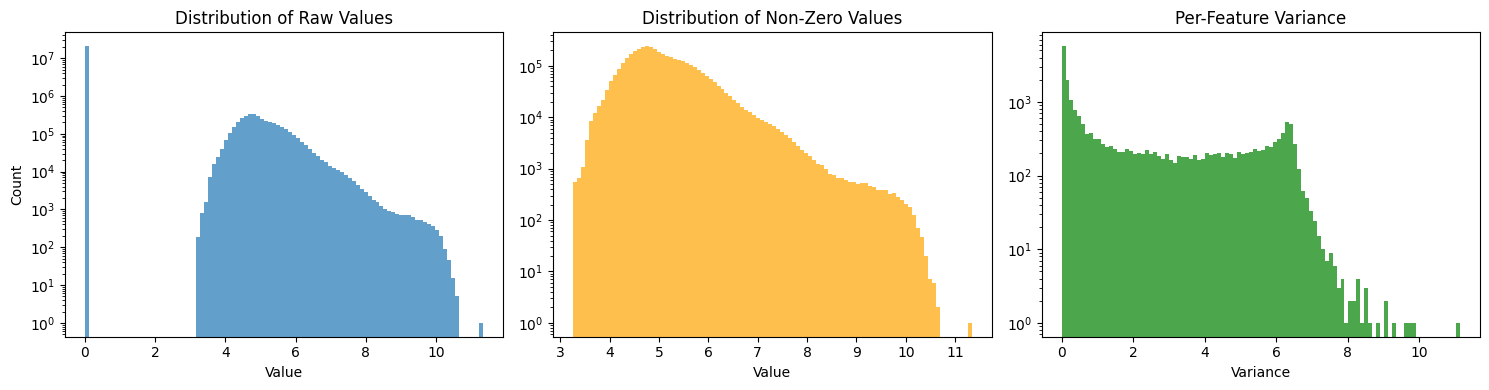

In [19]:
# Basic statistics of raw data
print("Raw data statistics:")
print(f"  Shape: {data_raw.shape}")
print(f"  Min: {data_raw.min():.4f}")
print(f"  Max: {data_raw.max():.4f}")
print(f"  Mean: {data_raw.mean():.4f}")
print(f"  Std: {data_raw.std():.4f}")
print(f"  % zeros: {(data_raw == 0).sum() / data_raw.size * 100:.2f}%")

# Distribution of values
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Histogram of all values (subsample for speed)
sample_values = data_raw.flatten()[::100]
axes[0].hist(sample_values, bins=100, alpha=0.7)
axes[0].set_title("Distribution of Raw Values")
axes[0].set_xlabel("Value")
axes[0].set_ylabel("Count")
axes[0].set_yscale("log")

# Non-zero values only
nonzero_values = sample_values[sample_values > 0]
axes[1].hist(nonzero_values, bins=100, alpha=0.7, color="orange")
axes[1].set_title("Distribution of Non-Zero Values")
axes[1].set_xlabel("Value")
axes[1].set_yscale("log")

# Per-feature variance
feature_var = data_raw.var(axis=0)
axes[2].hist(feature_var, bins=100, alpha=0.7, color="green")
axes[2].set_title("Per-Feature Variance")
axes[2].set_xlabel("Variance")
axes[2].set_yscale("log")

plt.tight_layout()
plt.show()

## 4. TrajectoryNet Preprocessing: log1p + z-score

In [20]:
def trajectorynet_preprocess(data: np.ndarray) -> Tuple[np.ndarray, StandardScaler]:
    """
    Apply TrajectoryNet preprocessing: log1p + z-score normalization.

    Returns:
        normalized: Normalized data
        scaler: Fitted StandardScaler for inverse transform
    """
    print("Applying TrajectoryNet preprocessing...")

    # Step 1: log1p transform
    print("  Step 1: log1p transform")
    data_log = np.log1p(data)
    print(f"    After log1p: mean={data_log.mean():.4f}, std={data_log.std():.4f}")

    # Step 2: z-score normalization (per-feature)
    print("  Step 2: z-score normalization")
    scaler = StandardScaler()
    normalized = scaler.fit_transform(data_log)
    print(
        f"    After z-score: mean={normalized.mean():.4f}, std={normalized.std():.4f}"
    )

    return normalized, scaler


# Apply preprocessing
data_normalized, scaler = trajectorynet_preprocess(data_raw)

Applying TrajectoryNet preprocessing...
  Step 1: log1p transform
    After log1p: mean=0.2954, std=0.6685
  Step 2: z-score normalization
    After z-score: mean=-0.0000, std=0.9880


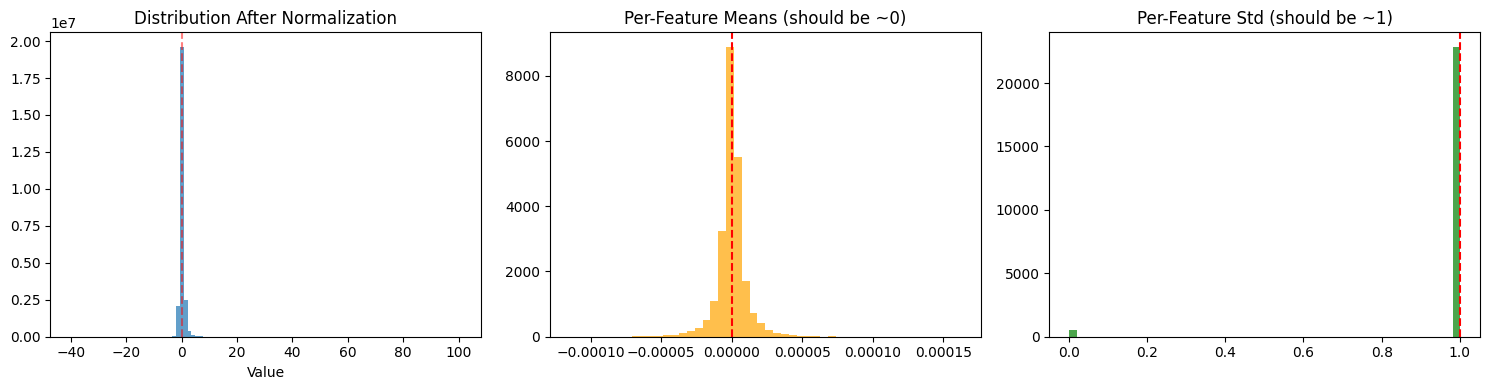

In [21]:
# Visualize normalized data
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sample_norm = data_normalized.flatten()[::100]

axes[0].hist(sample_norm, bins=100, alpha=0.7)
axes[0].set_title("Distribution After Normalization")
axes[0].set_xlabel("Value")
axes[0].axvline(x=0, color="r", linestyle="--", alpha=0.5)

# Per-feature mean (should be ~0)
feature_mean = data_normalized.mean(axis=0)
axes[1].hist(feature_mean, bins=50, alpha=0.7, color="orange")
axes[1].set_title("Per-Feature Means (should be ~0)")
axes[1].axvline(x=0, color="r", linestyle="--")

# Per-feature std (should be ~1)
feature_std = data_normalized.std(axis=0)
axes[2].hist(feature_std, bins=50, alpha=0.7, color="green")
axes[2].set_title("Per-Feature Std (should be ~1)")
axes[2].axvline(x=1, color="r", linestyle="--")

plt.tight_layout()
plt.show()

## 5. PCA Dimensionality Reduction

In [22]:
def apply_pca(data: np.ndarray, n_components: int) -> Tuple[np.ndarray, PCA]:
    """
    Apply PCA dimensionality reduction.

    Returns:
        pcs: PCA-reduced data (n_cells, n_components)
        pca: Fitted PCA model
    """
    print(f"Applying PCA (n_components={n_components})...")

    pca = PCA(n_components=n_components, random_state=SEED)
    pcs = pca.fit_transform(data)

    explained_var = pca.explained_variance_ratio_.sum()
    print(f"  ✓ Explained variance: {explained_var:.4f} ({explained_var * 100:.2f}%)")

    return pcs, pca


# Compute PCA for all dimensions
pca_results = {}
for dim in PCA_DIMS:
    pcs, pca = apply_pca(data_normalized, dim)
    pca_results[dim] = {"pcs": pcs, "pca": pca}

Applying PCA (n_components=5)...
  ✓ Explained variance: 0.0370 (3.70%)
Applying PCA (n_components=100)...
  ✓ Explained variance: 0.0612 (6.12%)


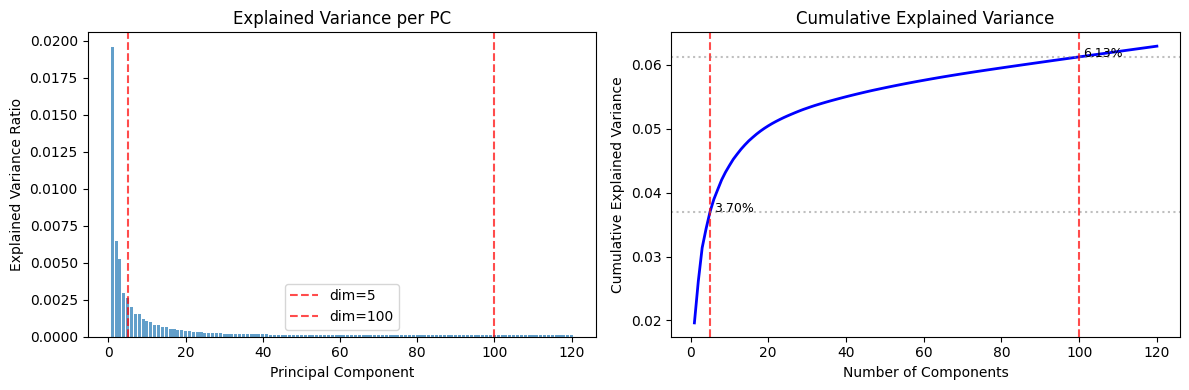

In [23]:
# Visualize explained variance
max_dim = max(PCA_DIMS)
pca_full = PCA(
    n_components=min(max_dim + 20, data_normalized.shape[1]), random_state=SEED
)
pca_full.fit(data_normalized)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Individual explained variance
axes[0].bar(
    range(1, len(pca_full.explained_variance_ratio_) + 1),
    pca_full.explained_variance_ratio_,
    alpha=0.7,
)
axes[0].set_xlabel("Principal Component")
axes[0].set_ylabel("Explained Variance Ratio")
axes[0].set_title("Explained Variance per PC")
for dim in PCA_DIMS:
    axes[0].axvline(x=dim, color="r", linestyle="--", alpha=0.7, label=f"dim={dim}")
axes[0].legend()

# Cumulative explained variance
cumsum = np.cumsum(pca_full.explained_variance_ratio_)
axes[1].plot(range(1, len(cumsum) + 1), cumsum, "b-", linewidth=2)
axes[1].set_xlabel("Number of Components")
axes[1].set_ylabel("Cumulative Explained Variance")
axes[1].set_title("Cumulative Explained Variance")
for dim in PCA_DIMS:
    axes[1].axvline(x=dim, color="r", linestyle="--", alpha=0.7)
    axes[1].axhline(y=cumsum[dim - 1], color="gray", linestyle=":", alpha=0.5)
    axes[1].text(dim + 1, cumsum[dim - 1], f"{cumsum[dim - 1]:.2%}", fontsize=9)

plt.tight_layout()
plt.show()

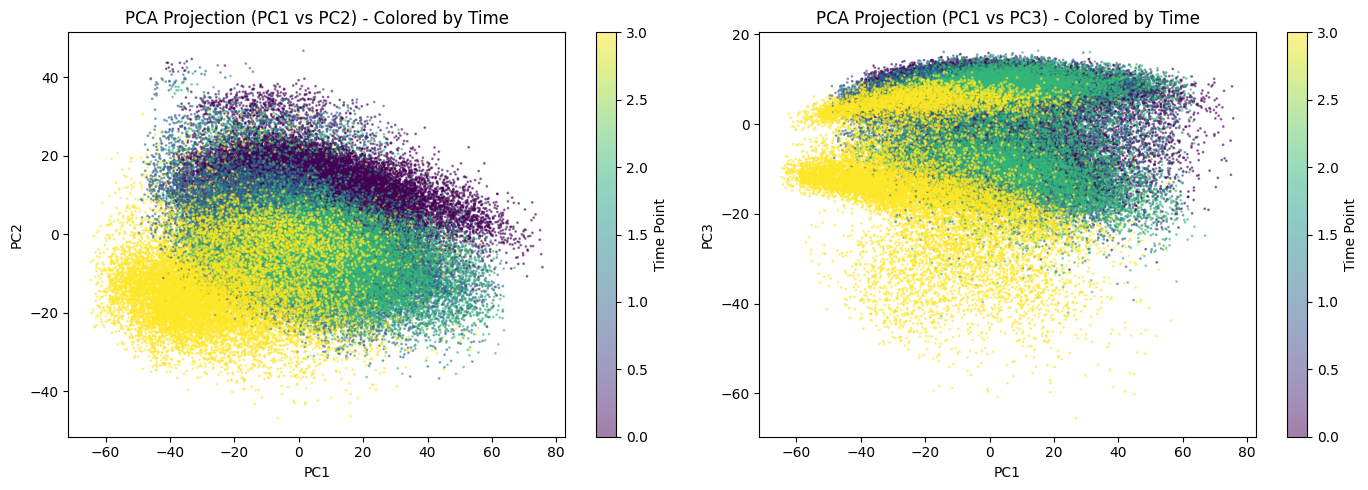

In [24]:
# Visualize PCA projections (first 2 PCs) colored by time if available
if time_labels is not None:
    pcs_5d = pca_results[5]["pcs"]

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # PC1 vs PC2
    scatter = axes[0].scatter(
        pcs_5d[:, 0], pcs_5d[:, 1], c=time_labels, cmap="viridis", alpha=0.5, s=1
    )
    axes[0].set_xlabel("PC1")
    axes[0].set_ylabel("PC2")
    axes[0].set_title("PCA Projection (PC1 vs PC2) - Colored by Time")
    plt.colorbar(scatter, ax=axes[0], label="Time Point")

    # PC1 vs PC3
    scatter = axes[1].scatter(
        pcs_5d[:, 0], pcs_5d[:, 2], c=time_labels, cmap="viridis", alpha=0.5, s=1
    )
    axes[1].set_xlabel("PC1")
    axes[1].set_ylabel("PC3")
    axes[1].set_title("PCA Projection (PC1 vs PC3) - Colored by Time")
    plt.colorbar(scatter, ax=axes[1], label="Time Point")

    plt.tight_layout()
    plt.show()
else:
    print("⚠ No time labels available for coloring")

## 6. Split by Time Points

In [25]:
def split_by_time(pcs: np.ndarray, time_labels: np.ndarray) -> Dict[int, np.ndarray]:
    """
    Split data by time points.

    Returns:
        Dictionary mapping time index to data array
    """
    unique_times = np.unique(time_labels)
    print(f"Splitting into {len(unique_times)} time points...")

    time_data = {}
    for t in sorted(unique_times):
        mask = time_labels == t
        time_data[int(t)] = pcs[mask]
        print(f"  Time {t}: {mask.sum()} samples")

    return time_data


# Split data by time (using 5D for visualization)
if time_labels is not None:
    time_data_5d = split_by_time(pca_results[5]["pcs"], time_labels)
else:
    print("⚠ Cannot split without time labels")

Splitting into 4 time points...
  Time 0: 23911 samples
  Time 1: 28815 samples
  Time 2: 31134 samples
  Time 3: 22082 samples


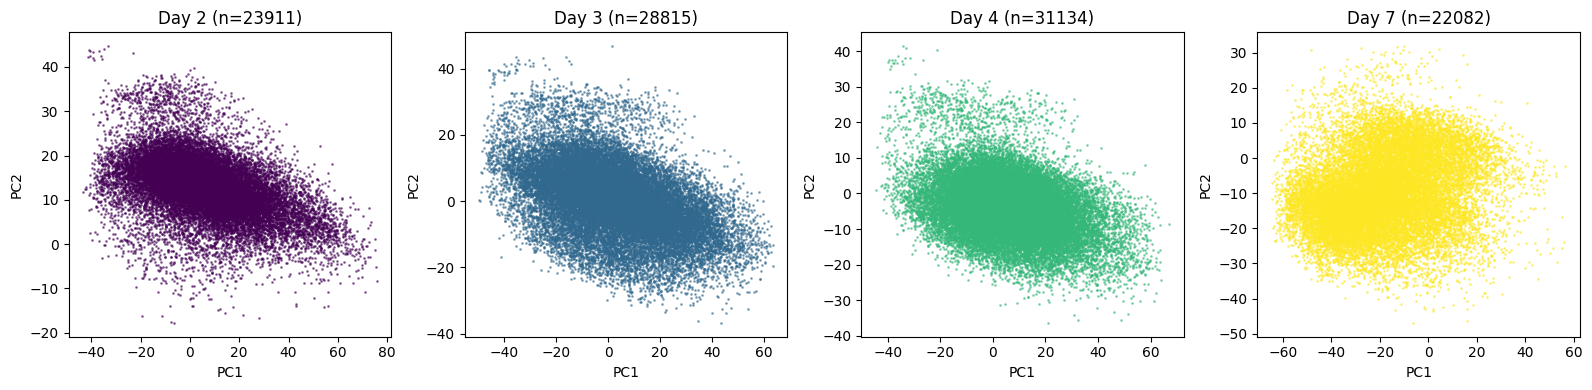

In [26]:
# Visualize each time point separately
if time_labels is not None:
    n_times = len(time_data_5d)
    fig, axes = plt.subplots(1, n_times, figsize=(4 * n_times, 4))
    if n_times == 1:
        axes = [axes]

    colors = plt.cm.viridis(np.linspace(0, 1, n_times))

    for i, (t, data) in enumerate(sorted(time_data_5d.items())):
        axes[i].scatter(data[:, 0], data[:, 1], c=[colors[i]], alpha=0.5, s=1)
        axes[i].set_xlabel("PC1")
        axes[i].set_ylabel("PC2")
        orig_t = unique_times[t] if unique_times else t
        axes[i].set_title(f"Day {orig_t} (n={len(data)})")

    plt.tight_layout()
    plt.show()

## 7. Train/Test Split

In [27]:
def train_test_split_by_time(
    time_data: Dict[int, np.ndarray], train_ratio: float = 0.85, seed: int = 42
) -> Tuple[Dict[int, np.ndarray], Dict[int, np.ndarray]]:
    """
    Split each time point into train/test sets.

    Returns:
        train_data, test_data: Dictionaries with split data
    """
    np.random.seed(seed)

    train_data = {}
    test_data = {}

    print(f"Train/test split (ratio={train_ratio}):")
    for t, data in time_data.items():
        n = len(data)
        n_train = int(n * train_ratio)

        indices = np.random.permutation(n)
        train_idx = indices[:n_train]
        test_idx = indices[n_train:]

        train_data[t] = data[train_idx]
        test_data[t] = data[test_idx]

        print(f"  Time {t}: {len(train_idx)} train, {len(test_idx)} test")

    return train_data, test_data

## 8. Save Preprocessed Data

In [28]:
def save_preprocessed(
    output_dir: str,
    dim: int,
    train_data: Dict[int, np.ndarray],
    test_data: Dict[int, np.ndarray],
    scaler: StandardScaler,
    pca: PCA,
    unique_times: List = None,
):
    """
    Save preprocessed data to npz files.
    Applies StandardScaler to PCA output for comparable W1 metrics with other papers.
    """
    dim_dir = os.path.join(output_dir, f"dim{dim}")
    os.makedirs(dim_dir, exist_ok=True)

    print(f"\nSaving to {dim_dir}/")

    # ===== CRITICAL: StandardScaler on PCA output =====
    # This is required to match other papers's preprocessing
    # They normalize PCA components to zero mean, unit variance
    all_train_pcs = np.concatenate(
        [train_data[t] for t in sorted(train_data.keys())], axis=0
    )
    pca_scaler = StandardScaler()
    pca_scaler.fit(all_train_pcs)
    print(f"  Fitting PCA scaler on {len(all_train_pcs)} train samples")
    print(f"    mean (first 3 PCs): {pca_scaler.mean_[:3]}")
    print(f"    std  (first 3 PCs): {pca_scaler.scale_[:3]}")

    # Apply scaler to all data (both train and test)
    for t in sorted(train_data.keys()):
        train_data[t] = pca_scaler.transform(train_data[t]).astype(np.float32)
        test_data[t] = pca_scaler.transform(test_data[t]).astype(np.float32)

    # Verify: should now have ~0 mean, ~1 std
    all_scaled = np.concatenate([train_data[t] for t in train_data.keys()], axis=0)
    print(
        f"  After PCA scaling: mean={all_scaled.mean():.6f}, std={all_scaled.std():.6f}"
    )

    # Save data per time point
    for t in sorted(train_data.keys()):
        # Training data
        train_path = os.path.join(dim_dir, f"time_{t}.npz")
        np.savez(train_path, pcs=train_data[t])
        print(f"  ✓ {train_path}")

        # Test data
        test_dir = os.path.join(dim_dir, "test")
        os.makedirs(test_dir, exist_ok=True)
        test_path = os.path.join(test_dir, f"time_{t}.npz")
        np.savez(test_path, pcs=test_data[t])

    # Save scalers and PCA
    joblib.dump(
        scaler, os.path.join(dim_dir, "scaler_log1p.pkl")
    )  # Original log1p scaler
    joblib.dump(
        pca_scaler, os.path.join(dim_dir, "scaler.pkl")
    )  # PCA output scaler (for inverse transform)
    joblib.dump(pca, os.path.join(dim_dir, "pca.pkl"))
    print(f"  ✓ scaler.pkl (PCA output), scaler_log1p.pkl, pca.pkl")

    # Save metadata
    meta_path = os.path.join(dim_dir, "metadata.txt")
    with open(meta_path, "w") as f:
        f.write(f"PCA dimension: {dim}\n")
        f.write(f"Explained variance: {pca.explained_variance_ratio_.sum():.4f}\n")
        f.write(f"Number of time points: {len(train_data)}\n")
        f.write(f"Train ratio: {TRAIN_RATIO}\n")
        f.write(f"PCA scaler applied: True (zero mean, unit variance)\n")
        for t in sorted(train_data.keys()):
            orig_t = unique_times[t] if unique_times else t
            f.write(
                f"  Time {t} (original: {orig_t}): {len(train_data[t])} train, {len(test_data[t])} test\n"
            )
    print(f"  ✓ metadata.txt")

In [29]:
# Process and save all dimensions
if time_labels is not None:
    for dim in PCA_DIMS:
        print(f"\n{'=' * 50}")
        print(f"Processing dim={dim}")
        print(f"{'=' * 50}")

        # Get PCA results
        pcs = pca_results[dim]["pcs"]
        pca = pca_results[dim]["pca"]

        # Split by time
        time_data = split_by_time(pcs, time_labels)

        # Train/test split
        train_data, test_data = train_test_split_by_time(time_data, TRAIN_RATIO, SEED)

        # Save
        save_preprocessed(
            OUTPUT_DIR, dim, train_data, test_data, scaler, pca, unique_times
        )

    print("\n" + "=" * 50)
    print("✓ Done! Data saved to:", OUTPUT_DIR)
    print("=" * 50)
else:
    print("⚠ Cannot save without time labels. Please provide metadata.")


Processing dim=5
Splitting into 4 time points...
  Time 0: 23911 samples
  Time 1: 28815 samples
  Time 2: 31134 samples
  Time 3: 22082 samples
Train/test split (ratio=0.85):
  Time 0: 20324 train, 3587 test
  Time 1: 24492 train, 4323 test
  Time 2: 26463 train, 4671 test
  Time 3: 18769 train, 3313 test

Saving to /projects/static2dynamic/datasets/Multiome/dim5/
  Fitting PCA scaler on 90048 train samples
    mean (first 3 PCs): [-0.00635854  0.00030743 -0.00710676]
    std  (first 3 PCs): [21.17413075 12.18532612 10.97468716]
  After PCA scaling: mean=-0.000000, std=1.000000
  ✓ /projects/static2dynamic/datasets/Multiome/dim5/time_0.npz
  ✓ /projects/static2dynamic/datasets/Multiome/dim5/time_1.npz
  ✓ /projects/static2dynamic/datasets/Multiome/dim5/time_2.npz
  ✓ /projects/static2dynamic/datasets/Multiome/dim5/time_3.npz
  ✓ scaler.pkl (PCA output), scaler_log1p.pkl, pca.pkl
  ✓ metadata.txt

Processing dim=100
Splitting into 4 time points...
  Time 0: 23911 samples
  Time 1: 288

## 9. Verify Saved Data

In [30]:
# Verify saved data can be loaded
print("Verifying saved data...\n")

for dim in PCA_DIMS:
    dim_dir = os.path.join(OUTPUT_DIR, f"dim{dim}")
    if os.path.exists(dim_dir):
        print(f"dim{dim}/")
        for fname in sorted(os.listdir(dim_dir)):
            fpath = os.path.join(dim_dir, fname)
            if fname.endswith(".npz"):
                data = np.load(fpath)
                print(f"  {fname}: shape={data['pcs'].shape}")
            elif os.path.isdir(fpath):
                print(f"  {fname}/")
                for subfname in sorted(os.listdir(fpath)):
                    subfpath = os.path.join(fpath, subfname)
                    if subfname.endswith(".npz"):
                        data = np.load(subfpath)
                        print(f"    {subfname}: shape={data['pcs'].shape}")
        print()

Verifying saved data...

dim5/
  test/
    time_0.npz: shape=(3587, 5)
    time_1.npz: shape=(4323, 5)
    time_2.npz: shape=(4671, 5)
    time_3.npz: shape=(3313, 5)
  time_0.npz: shape=(20324, 5)
  time_1.npz: shape=(24492, 5)
  time_2.npz: shape=(26463, 5)
  time_3.npz: shape=(18769, 5)

dim100/
  test/
    time_0.npz: shape=(3587, 100)
    time_1.npz: shape=(4323, 100)
    time_2.npz: shape=(4671, 100)
    time_3.npz: shape=(3313, 100)
  time_0.npz: shape=(20324, 100)
  time_1.npz: shape=(24492, 100)
  time_2.npz: shape=(26463, 100)
  time_3.npz: shape=(18769, 100)



## 10. Generate Config Snippet

Use this to update your config files:

In [31]:
if time_labels is not None:
    n_times = len(np.unique(time_labels))

    for dim in PCA_DIMS:
        print(f"\n# Config for dim={dim}")
        print(f"# Add to conf/conf_classes/multi_dim{dim}.py\n")
        print(f"self.n_distributions = {n_times}")
        print("")
        print("# In DistributionConfig:")
        print("self.distributions = [")
        for t in range(n_times):
            orig_t = unique_times[t] if unique_times else t
            print(
                f'    MultiConfig(time={t}, dim=dim, file_path=f"{{base_dir}}/time_{t}.npz"),  # original: {orig_t}'
            )
        print("]")


# Config for dim=5
# Add to conf/conf_classes/multi_dim5.py

self.n_distributions = 4

# In DistributionConfig:
self.distributions = [
    MultiConfig(time=0, dim=dim, file_path=f"{base_dir}/time_0.npz"),  # original: 2
    MultiConfig(time=1, dim=dim, file_path=f"{base_dir}/time_1.npz"),  # original: 3
    MultiConfig(time=2, dim=dim, file_path=f"{base_dir}/time_2.npz"),  # original: 4
    MultiConfig(time=3, dim=dim, file_path=f"{base_dir}/time_3.npz"),  # original: 7
]

# Config for dim=100
# Add to conf/conf_classes/multi_dim100.py

self.n_distributions = 4

# In DistributionConfig:
self.distributions = [
    MultiConfig(time=0, dim=dim, file_path=f"{base_dir}/time_0.npz"),  # original: 2
    MultiConfig(time=1, dim=dim, file_path=f"{base_dir}/time_1.npz"),  # original: 3
    MultiConfig(time=2, dim=dim, file_path=f"{base_dir}/time_2.npz"),  # original: 4
    MultiConfig(time=3, dim=dim, file_path=f"{base_dir}/time_3.npz"),  # original: 7
]
